# P2.02 — What moves affordability within a municipality? Fixed-effects regressions

**Questions:** RQ3.3 (population growth, immigration and prices), RQ5.1 and RQ5.4 (short-term rentals and
prices, separated from the other drivers).

**Outcome:** log price-to-income (`log_pti`), the affordability indicator of p1. Coefficients times 100 are
percentage changes. **Drivers:** the change in foreign residents with a legal residence title (AIMA, 2014 to
2023) and the change in everyone else, both in % of last year's population (they add up to the population's
growth); completed dwellings in the previous three years per 1,000 dwellings; share of residents aged 65+; and
(mainland only) registered short-term rentals per 1,000 dwellings.
Income is *not* a driver because it is inside the outcome; its role is decomposed first.

**Design** (`src/pthousing/analysis/panel.py`): municipality fixed effects remove everything constant about a
place; year effects remove national shocks (mortgage rate, inflation); the tougher variant adds NUTS 3 × year
effects, so a coefficient comes from differences between municipalities of the same region. Standard errors
are clustered by municipality, and by NUTS 3 region as a check. Sample: 2016 to 2023 (prices start in 2016,
population and foreign residents end in 2023). Foreign residents are those holding a residence title on 31
December: the series jumps by a third in 2023, partly from processing of applications, so one specification stops
in 2022. Results are **adjusted associations**: construction responds to prices and people move
to where prices are rising, so none of this identifies a cause.

In [1]:
import pandas as pd

from pthousing.analysis import panel as pn
from pthousing.analysis import spatial
from pthousing.data import build_panel, interim
from pthousing.viz import charts, style

style.apply_style()
panel = build_panel.read("panel_municipality_year")
frame = pn.build_frame(panel)
print(frame.loc[frame["log_pti"].notna() & frame["pop_growth_pct"].notna()].shape)

(2336, 13)


## Step 0 — Price or income? Decomposing the change in price-to-income, 2016 to 2024
log PTI = log price per m² + log dwelling size − log income. Across municipalities, how much of the *differences*
in the deterioration comes from each part? (Shares of the variance of the change; they add to 100%.)

In [2]:
wide = frame.reset_index().pivot(index="muni_code", columns="year")
d_pti = wide["log_pti"][2024] - wide["log_pti"][2016]
d_price = wide["log_price_real"][2024] - wide["log_price_real"][2016]
d_income = wide["log_income_real"][2024] - wide["log_income_real"][2016]
parts = pd.DataFrame({"pti": d_pti, "price": d_price, "income": -d_income}).dropna()
parts["size"] = parts["pti"] - parts["price"] - parts["income"]
shares = {c: parts[c].cov(parts["pti"]) / parts["pti"].var() for c in ("price", "income", "size")}
decomp = pd.DataFrame(
    {
        "component": ["Price per m2", "Income (sign reversed)", "Dwelling size"],
        "median_change_log": [parts[c].median() for c in ("price", "income", "size")],
        "variance_share": list(shares.values()),
    }
)
decomp.loc[len(decomp)] = ["Price-to-income", parts["pti"].median(), sum(shares.values())]
style.save_table(decomp, "p2", "pti_change_decomposition")
print(f"{len(parts)} municipalities")
print(decomp.round(3).to_string(index=False))
print("corr of 2016-24 price growth and income growth:", round(d_price.corr(d_income), 2))

296 municipalities
             component  median_change_log  variance_share
          Price per m2              0.410           0.922
Income (sign reversed)             -0.254           0.091
         Dwelling size              0.021          -0.013
       Price-to-income              0.178           1.000
corr of 2016-24 price growth and income growth: -0.31


## Step 1 — The specification ladder

In [3]:
X = [
    "pop_change_ex_foreign_pct",
    "foreign_change_pct",
    "completions_per_1000",
    "pop_65plus_pct",
]
XAL = [*X, "al_per_1000"]
mainland = {"territory": ["continente"]}
metro = {"exclude_district": ["Lisboa", "Setúbal", "Porto"]}
SPECS = {
    "Municipality + year effects": pn.Spec("log_pti", X),
    "Municipality + region-year effects": pn.Spec("log_pti", X, effects="region_year"),
    "Errors clustered by region": pn.Spec("log_pti", X, cluster="region"),
    "Drivers lagged one year": pn.Spec("log_pti", X, lag=1),
    "Without Lisboa, Setúbal, Porto": pn.Spec("log_pti", X, sample=metro),
    "Through 2022 (before the 2023 jump)": pn.Spec("log_pti", X, years=(2016, 2022)),
    "Mainland, with rentals": pn.Spec("log_pti", XAL, sample=mainland),
    "Mainland, with rentals, region-year": pn.Spec(
        "log_pti", XAL, effects="region_year", sample=mainland
    ),
}
MAIN, COMPARE = "Municipality + year effects", "Municipality + region-year effects"
fits = {name: pn.fit(frame, spec) for name, spec in SPECS.items()}
ladder = pd.concat([pn.coef_table(res, name) for name, res in fits.items()], ignore_index=True)
style.save_table(ladder, "p2", "fe_regressions_pti")
show = ladder.assign(term=ladder["term"].map(pn.LABELS))
print(
    show[["spec", "term", "coef", "se", "p", "coef_per_sd", "n_obs", "n_munis", "r2"]]
    .round(4)
    .to_string(index=False)
)

                               spec                                       term    coef     se      p  coef_per_sd  n_obs  n_munis     r2
        Municipality + year effects       Other population change (pp of pop.)  0.0098 0.0029 0.0006       0.0140   2336      298 0.0681
        Municipality + year effects       Foreign resident change (pp of pop.)  0.0433 0.0099 0.0000       0.0205   2336      298 0.0681
        Municipality + year effects Completions, 3 years (per 1,000 dwellings)  0.0115 0.0020 0.0000       0.0228   2336      298 0.0681
        Municipality + year effects                   Population aged 65+ (pp) -0.0072 0.0068 0.2912      -0.0059   2336      298 0.0681
 Municipality + region-year effects       Other population change (pp of pop.)  0.0045 0.0027 0.0972       0.0050   2336      298 0.0155
 Municipality + region-year effects       Foreign resident change (pp of pop.)  0.0306 0.0086 0.0004       0.0111   2336      298 0.0155
 Municipality + region-year effects Compl

For comparison, the earlier specification that does not split foreign residents out of population growth:

In [4]:
total_pop = pn.coef_table(
    pn.fit(frame, pn.Spec("log_pti", ["pop_growth_pct", *X[2:]])), "Total population growth"
)
style.save_table(total_pop, "p2", "fe_regressions_pti_total_population")
print(total_pop[["term", "coef", "se", "p", "coef_per_sd", "r2"]].round(4).to_string(index=False))

                term    coef     se      p  coef_per_sd     r2
      pop_growth_pct  0.0096 0.0028 0.0005       0.0130 0.0544
completions_per_1000  0.0126 0.0020 0.0000       0.0249 0.0544
      pop_65plus_pct -0.0107 0.0068 0.1164      -0.0087 0.0544


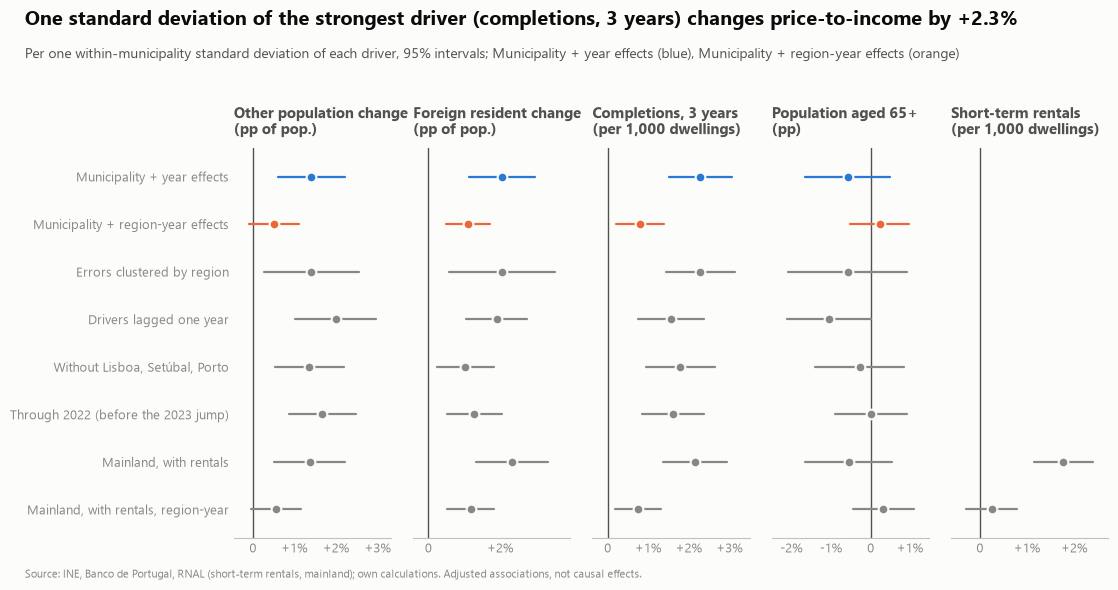

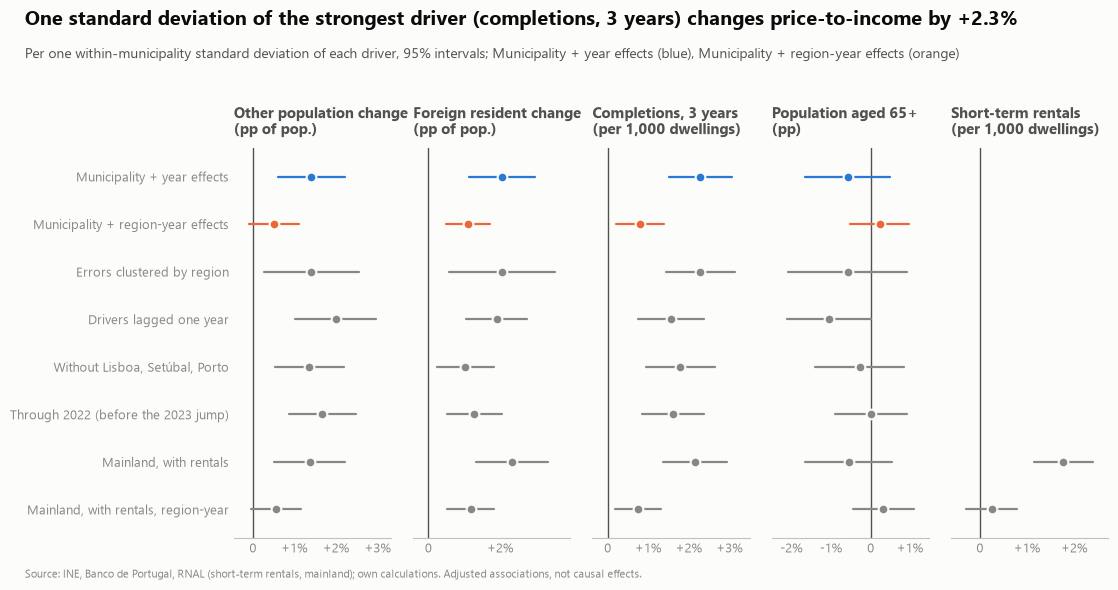

In [5]:
fig = charts.coef_ladder(ladder, pn.LABELS, MAIN, COMPARE, "price-to-income")
style.save_fig(fig, "p2", "fe_coefficients_pti")
fig

## Step 2 — Checks: collinearity and leftover spatial dependence

In [6]:
main_fit = fits[MAIN]
vif = pn.vif(main_fit.sample_frame, X)
print("VIF after removing the fixed effects:", vif.round(2).to_dict())
geo = interim.read("caop_municipalities")
w = spatial.build_weights(geo)
resid = pn.residuals_by_year(main_fit)
resid_moran = spatial.moran_by_year(
    resid.rename(columns={"residual": "resid"}), "resid", w, [2016, 2018, 2020, 2021, 2023]
)
style.save_table(resid_moran, "p2", "fe_residual_moran")
print(resid_moran.round(3).to_string(index=False))

VIF after removing the fixed effects: {'pop_change_ex_foreign_pct': 1.16, 'foreign_change_pct': 1.19, 'completions_per_1000': 1.02, 'pop_65plus_pct': 1.08}


 year     I  expected  z_sim  p_sim   n
 2016 0.222    -0.003  5.719  0.001 296
 2018 0.134    -0.003  3.682  0.002 298
 2020 0.081    -0.004  2.071  0.024 278
 2021 0.031    -0.003  0.824  0.198 293
 2023 0.391    -0.003  9.874  0.001 294


## Appendix — The price model with income (why income is not a driver)
Real median income moves slowly (a typical municipality's income changes by about 1% a year, its price by
15%), and municipalities whose prices rose most had the *smallest* income growth. The coefficient on income in a
price regression is therefore negative and large, which reflects convergence in incomes and divergence in
prices, not an effect of income on price.

In [7]:
XP = ["log_income_real", *X]
appendix = pd.concat(
    [
        pn.coef_table(pn.fit(frame, pn.Spec("log_price_real", XP)), "Price, municipality + year"),
        pn.coef_table(
            pn.fit(frame, pn.Spec("log_price_real", XP, effects="region_year")),
            "Price, region-year",
        ),
    ],
    ignore_index=True,
)
style.save_table(appendix, "p2", "fe_regressions_price")
print(appendix[["spec", "term", "coef", "se", "p", "n_obs", "r2"]].round(4).to_string(index=False))

                      spec                      term    coef     se      p  n_obs     r2
Price, municipality + year           log_income_real -0.9104 0.2650 0.0006   2336 0.0622
Price, municipality + year pop_change_ex_foreign_pct  0.0058 0.0025 0.0187   2336 0.0622
Price, municipality + year        foreign_change_pct  0.0246 0.0081 0.0023   2336 0.0622
Price, municipality + year      completions_per_1000  0.0093 0.0020 0.0000   2336 0.0622
Price, municipality + year            pop_65plus_pct  0.0066 0.0069 0.3433   2336 0.0622
        Price, region-year           log_income_real -0.4089 0.2652 0.1233   2336 0.0121
        Price, region-year pop_change_ex_foreign_pct  0.0025 0.0025 0.3154   2336 0.0121
        Price, region-year        foreign_change_pct  0.0186 0.0078 0.0176   2336 0.0121
        Price, region-year      completions_per_1000  0.0033 0.0017 0.0481   2336 0.0121
        Price, region-year            pop_65plus_pct  0.0080 0.0073 0.2689   2336 0.0121


## Findings

1. **Prices, not incomes, drive where affordability worsened (step 0).** Between 2016 and 2024 the median
   municipality's real price per m² rose 51% (log 0.41) and its real income 29% (0.25), so price-to-income rose 19%.
   Across municipalities, 92% of the variance of the deterioration is the price change and 9% the income change
   (dwelling size: −1%). Price growth and income growth are negatively correlated (−0.31): the places where prices
   rose most are not those where incomes rose most.
2. **Foreign residents stand out among the drivers.** One more percentage point of the population added through
   foreign residents with a legal title goes with +4.3% in price-to-income (p < 0.001); a point of other population
   change with +1.0%. Per within-municipality standard deviation that is +2.0% and +1.4%, against +2.3% for recent
   completions. With NUTS 3 × year effects the foreign-resident coefficient is still +3.1% (p < 0.001) while the
   other-population one falls to +0.45% (p = 0.10). It holds with region-clustered errors (p = 0.006), lagged
   drivers (+4.8%), without Lisboa, Setúbal and Porto (+2.3%, p = 0.01) and when 2023 is dropped (+3.3%,
   p < 0.001). The price-per-m² model gives the same sign (+2.5%, +1.9% with region-year effects). Splitting
   foreign residents out raises the explained share from 5.4% (total population growth) to 6.8%.
3. **Read it as an association with where foreign residents settle, not as an effect of immigrants.** A foreign
   resident adds one person, yet the coefficient is four times that of other population, so the variable also
   stands for what is concentrated with them: arrival in the tightest local markets beyond what the region absorbs,
   rental demand, and the processing of residence titles (the count may include people who were already living in
   the municipality before their title was issued). The series jumps by a third in 2023; the result survives dropping
   that year.
4. **The observed drivers still explain little.** After removing municipality and year effects they account for
   6.8% of the variation in log price-to-income (1.6% with region-year effects). Collinearity is not the issue
   (VIF 1.0 to 1.2).
5. **Construction follows prices, not the reverse.** Completions are positively associated with price-to-income
   (+1.15% per completed dwelling per 1,000, +0.46% with region-year effects); this is supply responding to price. It
   does not estimate what *extra* supply would do; that needs the simulator (p4) or a design with exogenous supply.
6. **Short-term rentals: an association that does not survive the region.** On the mainland, 10 more registered
   units per 1,000 dwellings go with +3.4% (p < 0.001), but with region-year effects the coefficient is 0.07% per
   unit (p = 0.37). Rentals concentrate in the Algarve, Lisboa and Porto, where prices rose for other reasons too. The
   series is the stock of units still registered today, which understates the past and so overstates its growth
   (data_quality.md).
7. **Ageing: no robust association** (sign changes across specifications).

**Limits.** The residuals are still spatially correlated in some years (Moran's I 0.03 to 0.39; 0.39 in 2023), so
standard errors clustered by municipality are likely too small; clustering by region (26 clusters) keeps the
conclusions, but few clusters are themselves a caveat. The sample is eight years. Foreign residents are those with a
residence title (AIMA via INE, 2014 to 2023), not people counted at a census, and the 2024 value is not available.
Nationalities are not used (they are in the interim table), second homes are not in the panel, and municipal income
is smooth and noisy at the same time, which is why income is decomposed rather than used as a driver.